# Paso 3 · Limpieza, estructuración y preparación de los datos

| | |
|---|---|
| **IDs del enunciado** | P2.1, P2.2, P2.3, P2.4, P2.5, P2.6 · entregable P2.E1, P2.E2, P2.E3, P2.E4 · F2 |
| **Fase** | F2 · Preparar (CRISP-DM: *Data Preparation*) |
| **Historia** | HU-03 · Sprint S6 (MVP en S2) |
| **Entregables** | este notebook + `db/processed/train.csv`, `test.csv`, `imputacion.json`, `feature_list.json` y `limites_atipicos.json` |

| ID | Qué se demuestra | Sección |
|---|---|---|
| **P2.1 / P2.E1** | Nulos (conteo, % y mapa), duplicados exactos y por ID, categorías y rangos inválidos, imputación | 1–3 |
| **P2.6 / P2.E4** | División train/test estratificada **antes** de imputar, escalar o codificar | 2 |
| **P2.4** | Seis variables nuevas con justificación de negocio y su señal | 4 |
| **P2.2 / P2.E2** | One-Hot (nominales) y Ordinal (ordinales) con el mapeo | 5 |
| **P2.3 / P2.E2** | `MinMaxScaler` frente a `StandardScaler` y la elección | 6 |
| **P2.E3** | Selección de características (Spearman, información mutua, importancia de árboles) | 7 |
| **P2.5** | PCA: varianza acumulada y decisión | 8 |
| — | Exportación reproducible a `db/processed/` con SHA-256 | 9 |

**Objetivo.** Convertir el CSV crudo en un conjunto de entrenamiento y otro de prueba **limpios, sin nulos
ni duplicados y sin fuga de información**, usando exactamente la misma lógica que usa el modelo servido. El
notebook no reimplementa nada: importa `credit_risk.data` y `credit_risk.features` y muestra, paso a paso,
qué hace cada función y por qué.

**Aprendizaje de la unidad (Módulo 1 · Unidad 2).** Preparar datos es una secuencia con un orden que no se
puede alterar: primero las **reglas fijas** (duplicados, catálogos, rangos válidos), que no miran
estadísticos del dataset; después la **partición** train/test; y solo entonces todo lo que *aprende* de los
datos (medianas, modas, escaladores, codificadores, límites de atípicos), ajustado **solo en train**. Si
ese orden se invierte, la prueba deja de ser un examen honesto (*data leakage*). En lo práctico se aprende a
auditar faltantes y duplicados, a imputar con criterio, a crear variables con sentido de negocio, a
codificar y escalar con scikit-learn y a decidir con datos si una reducción de dimensionalidad compensa.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
from dataclasses import asdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler

from credit_risk import config
from credit_risk.data import (ReporteLimpieza, aprender_imputacion, cargar_datos, cargar_procesados, dividir,
                              hash_archivo, limpiar, preparar_procesados, validar_dataset)
from credit_risk.features import Winsorizer, build_preprocessor, columnas_modelo, crear_variables, variable_original
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, SERIE, figura_front, guardar_json


def r4(valores) -> list:
    """Redondea a 4 decimales para exportar los datos de una figura al front."""
    return np.round(np.asarray(valores, dtype=float), 4).tolist()


T, ID = config.TARGET, config.ID_COL
crudo = cargar_datos()
print(f"Dataset crudo: {ruta(config.RAW_DATA_PATH)} → {crudo.shape[0]:,} filas × {crudo.shape[1]} columnas")
contrato = validar_dataset(crudo)
pd.Series({k: v for k, v in contrato.items() if k != "columnas_faltantes"}, name="cumple").to_frame()

Dataset crudo: db/credit_risk.csv → 12,144 filas × 21 columnas


,cumple
columnas_minimas,True
target_binario,True
prevalencia_5_40,True
filas_min_1000,True
texto_no_vacio_95,True
texto_distintos_200,True
nulos_en_3_columnas,True
hay_duplicados,True
hay_atipicos_ingreso,True
diccionario_existe,True


El contrato de datos (`validar_dataset`) confirma que el crudo tiene lo que el paso 3 debe resolver: nulos en
varias columnas, duplicados por ID y atípicos en el ingreso. A partir de aquí cada problema se mide y se
corrige.

## 1. P2.1 · Valores faltantes y duplicados
### 1.1 Reporte de nulos (conteo y porcentaje)

In [5]:
nulos = (pd.DataFrame({"nulos": crudo.isna().sum(), "pct_nulos": (crudo.isna().mean() * 100).round(2)})
         .query("nulos > 0").sort_values("nulos", ascending=False))
print(f"Columnas con nulos: {len(nulos)} de {crudo.shape[1]} · celdas nulas: {int(crudo.isna().sum().sum()):,} "
      f"({crudo.isna().mean().mean():.2%} del total)")
nulos

Columnas con nulos: 7 de 21 · celdas nulas: 4,088 (1.60% del total)


,nulos,pct_nulos
antiguedad_laboral_anios,1118,9.2100
ingreso_mensual,749,6.1700
relacion_deuda_ingreso,612,5.0400
situacion_laboral,494,4.0700
puntaje_buro,488,4.0200
tipo_vivienda,387,3.1900
texto_solicitud,240,1.9800


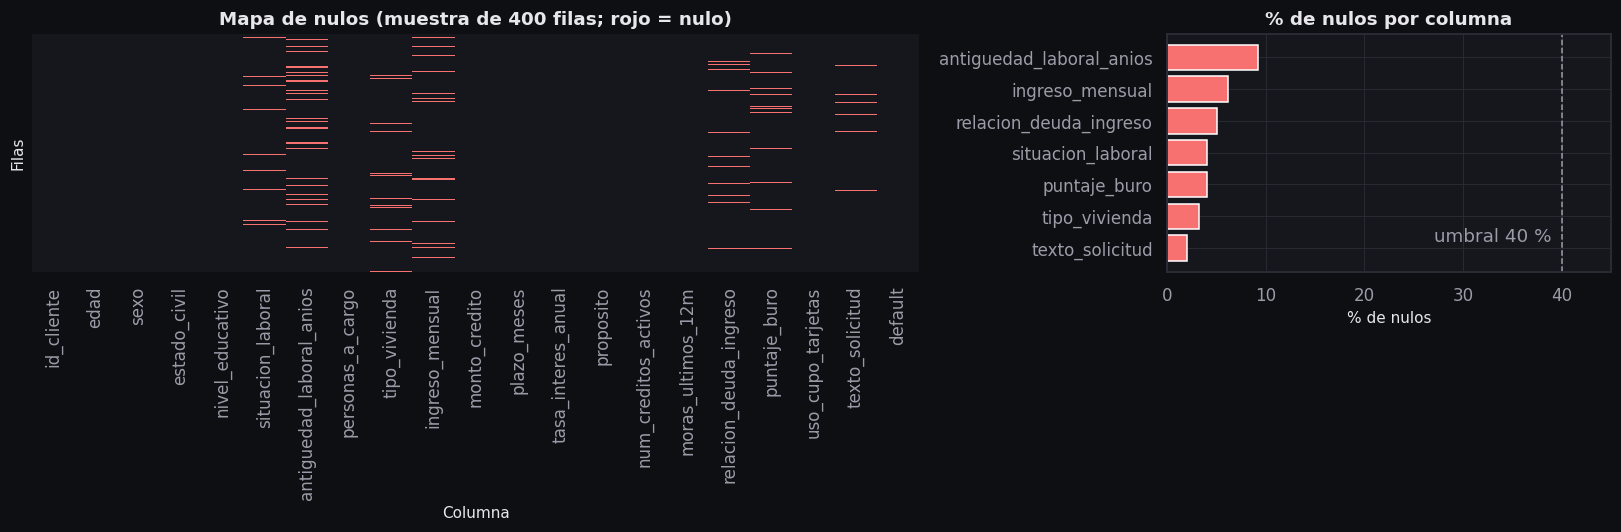

In [6]:
muestra = crudo.sample(400 if not FAST else 200, random_state=config.RANDOM_STATE)
mapa = muestra.isna().astype(int)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(mapa, cbar=False, cmap=[PALETA["panel"], PALETA["alto"]], yticklabels=False, ax=axes[0])
axes[0].set(title=f"Mapa de nulos (muestra de {len(muestra)} filas; rojo = nulo)", xlabel="Columna", ylabel="Filas")
axes[0].tick_params(axis="x", rotation=90)
axes[1].barh(nulos.index[::-1], nulos["pct_nulos"][::-1], color=PALETA["alto"])
axes[1].axvline(40, ls="--", color=PALETA["texto_suave"], lw=1)
axes[1].text(39, 0.2, "umbral 40 %", ha="right", color=PALETA["texto_suave"])
axes[1].set(title="% de nulos por columna", xlabel="% de nulos", xlim=(0, 45))
plt.show()
figura_front("heatmap", f"Mapa de nulos (muestra de {len(muestra)} filas)",
             {"x": list(mapa.columns), "y": muestra[ID].tolist(), "valores": mapa.to_numpy().tolist()},
             ejes={"x": "Columna", "y": "Fila (cliente)"}, clave="mapa_nulos", opciones={"escala": ["sin nulo", "nulo"]})
figura_front("barras_h", "% de nulos por columna",
             {"categorias": list(nulos.index), "series": [{"nombre": "% de nulos", "valores": r4(nulos["pct_nulos"])}],
              "referencias": [{"eje": "x", "valor": 40, "etiqueta": "umbral 40 %"}]},
             ejes={"x": "% de nulos", "y": "Columna"}, clave="pct_nulos_por_columna")

**Interpretación.** Solo 7 de las 21 columnas tienen nulos y suman el 1,60 % de las celdas. La que más
tiene es `antiguedad_laboral_anios` (9,21 %), seguida de `ingreso_mensual` (6,17 %) y `relacion_deuda_ingreso`
(5,04 %); **ninguna se acerca al umbral del 40 %**, así que no se elimina ninguna columna: todas se imputan. En
el mapa, los nulos aparecen como marcas aisladas repartidas entre esas columnas, sin bloques de filas vacías.

### 1.2 Duplicados, categorías mal escritas y valores fuera de rango

`limpiar(df, ReporteLimpieza())` aplica solo **reglas fijas** definidas en `config` (no calcula ningún
estadístico, así que puede ejecutarse antes de dividir): elimina duplicados exactos y por `id_cliente`,
normaliza las categorías contra el catálogo (espacios, mayúsculas), y convierte en `NaN` las edades fuera de
18–100, los montos e ingresos ≤ 0 y los valores fuera de los rangos válidos, para imputarlos después con
estadísticos de train.

In [7]:
print(f"En el crudo: duplicados exactos = {int(crudo.duplicated().sum())}, "
      f"IDs repetidos = {int(crudo[ID].duplicated().sum())}")
reporte = ReporteLimpieza()
limpio = limpiar(crudo, reporte)
rep = asdict(reporte)
filas_rep = [("Filas iniciales", "—", rep["filas_iniciales"]),
             ("Duplicados exactos eliminados", "todas", rep["duplicados_exactos"]),
             ("Duplicados por ID eliminados (tras los exactos)", ID, rep["duplicados_id"]),
             ("Edades fuera de 18–100 → NaN", "edad", rep["edades_invalidas"])]
filas_rep += [("Categoría fuera de catálogo → NaN", c, n) for c, n in rep["categorias_fuera_catalogo"].items()]
filas_rep += [("Valor ≤ 0 → NaN", c, n) for c, n in rep["no_positivos"].items()]
filas_rep += [(f"Fuera de rango {config.RANGOS_VALIDOS[c]} → NaN", c, n) for c, n in rep["fuera_de_rango"].items()]
filas_rep += [("Filas finales", "—", rep["filas_finales"])]
tabla_limpieza = pd.DataFrame(filas_rep, columns=["regla", "columna", "filas afectadas"])
dedup = crudo.drop_duplicates()
edades_malas = dedup.loc[dedup["edad"].notna() & ~dedup["edad"].between(*config.EDAD_VALIDA), "edad"]
print("Edades imposibles encontradas:", edades_malas.value_counts().sort_index().to_dict())
assert limpio.duplicated().sum() == 0 and limpio[ID].is_unique
tabla_limpieza

En el crudo: duplicados exactos = 144, IDs repetidos = 144


Edades imposibles encontradas: {1: 2, 2: 6, 120: 8, 150: 6, 999: 2}


,regla,columna,filas afectadas
0,Filas iniciales,—,12144
1,Duplicados exactos eliminados,todas,144
2,Duplicados por ID eliminados (tras los exactos),id_cliente,0
3,Edades fuera de 18–100 → NaN,edad,24
4,Categoría fuera de catálogo → NaN,sexo,0
5,Categoría fuera de catálogo → NaN,estado_civil,0
6,Categoría fuera de catálogo → NaN,nivel_educativo,0
7,Categoría fuera de catálogo → NaN,situacion_laboral,0
8,Categoría fuera de catálogo → NaN,tipo_vivienda,0
9,Categoría fuera de catálogo → NaN,proposito,0


**Lectura.** El crudo tenía 144 filas duplicadas exactas y 144 IDs repetidos; al quitar las
exactas ya no queda ningún ID repetido (0 duplicados por ID), es decir, los IDs repetidos eran justamente esas
copias. Había **24 edades imposibles** (1, 2, 120, 150 y 999 años) que pasan a nulo para imputarse. Ninguna
categoría estaba fuera del catálogo y no hubo montos ni ingresos ≤ 0 ni valores fuera de rango: esas reglas no
cambiaron nada en este archivo, pero quedan activas para los datos nuevos que lleguen por la API. Resultado:
**12.000 clientes únicos**.

## 2. P2.6 · División train/test **antes** de aprender cualquier estadístico

`dividir()` hace `train_test_split(test_size=0.2, stratify=default, random_state=42)`. Se ejecuta **antes**
de imputar, codificar o escalar: así las medianas, modas, categorías, medias y desviaciones se aprenden
solo con train y test permanece como un examen que el modelo nunca vio.

In [8]:
train_raw, test_raw = dividir(limpio)
tabla_div = pd.DataFrame({
    "filas": [len(limpio), len(train_raw), len(test_raw)],
    "impagos": [int(limpio[T].sum()), int(train_raw[T].sum()), int(test_raw[T].sum())],
    "tasa_default": [limpio[T].mean(), train_raw[T].mean(), test_raw[T].mean()],
    "celdas_nulas": [int(d.isna().sum().sum()) for d in (limpio, train_raw, test_raw)],
}, index=["Total (limpio)", "Train (80 %)", "Test (20 %)"])
assert not set(train_raw[ID]) & set(test_raw[ID]), "Un cliente no puede estar en train y en test"
tabla_div

,filas,impagos,tasa_default,celdas_nulas
Total (limpio),12000,4268,0.3557,4050
Train (80 %),9600,3414,0.3556,3235
Test (20 %),2400,854,0.3558,815


**Lectura.** La estratificación conserva la tasa de impago: 35,56 % en train (9.600 filas) y
35,58 % en test (2.400), frente a 35,57 % en el total. Ningún cliente está en los dos conjuntos. Los nulos
siguen ahí (3.235 celdas en train y 815 en test) a propósito: se imputan en el paso siguiente con
estadísticos de train.

## 3. P2.1 · Imputación aprendida **solo en train**

| Tipo | Estrategia | Justificación |
|---|---|---|
| Numéricas | **Mediana** de train | Robusta a la asimetría y a los atípicos de ingreso y monto |
| `situacion_laboral`, `tipo_vivienda` | Categoría **"Desconocido"** | No declarar la situación laboral o la vivienda puede ser informativo; no se inventa un valor |
| Otras categóricas | **Moda** de train | Regla general para datos nuevos (en este crudo no tienen nulos) |
| `texto_solicitud` | Marcador **"Sin texto"** | Explícito; `longitud_texto = 0` identifica estos casos |

Ninguna columna supera el 40 % de nulos, así que **no se elimina ninguna columna**.

In [9]:
reglas = aprender_imputacion(train_raw)
train_imp, test_imp = reglas.aplicar(train_raw), reglas.aplicar(test_raw)
cols_nulas = [c for c in limpio.columns if limpio[c].isna().any()]


def estrategia(c: str) -> tuple[str, object]:
    if c in reglas.mediana:
        return "mediana (train)", reglas.mediana[c]
    if c in reglas.moda:
        return "moda (train)", reglas.moda[c]
    if c in reglas.desconocido:
        return "categoría propia", reglas.desconocido[c]
    return "marcador", config.TEXTO_FALTANTE


tabla_imp = pd.DataFrame({
    "estrategia": [estrategia(c)[0] for c in cols_nulas],
    "valor_imputado": [estrategia(c)[1] for c in cols_nulas],
    "nulos_train_antes": train_raw[cols_nulas].isna().sum(),
    "nulos_test_antes": test_raw[cols_nulas].isna().sum(),
    "nulos_train_despues": train_imp[cols_nulas].isna().sum(),
    "nulos_test_despues": test_imp[cols_nulas].isna().sum(),
}).sort_values("nulos_train_antes", ascending=False)
assert train_imp.isna().sum().sum() == 0 and test_imp.isna().sum().sum() == 0
tabla_imp

,estrategia,valor_imputado,nulos_train_antes,nulos_test_antes,nulos_train_despues,nulos_test_despues
antiguedad_laboral_anios,mediana (train),9.0000,881,223,0,0
ingreso_mensual,mediana (train),"2,234,000.0000",577,162,0,0
relacion_deuda_ingreso,mediana (train),0.5555,488,114,0,0
situacion_laboral,categoría propia,Desconocido,384,101,0,0
puntaje_buro,mediana (train),715.0000,377,102,0,0
tipo_vivienda,categoría propia,Desconocido,316,64,0,0
texto_solicitud,marcador,Sin texto,192,45,0,0
edad,mediana (train),49.0000,20,4,0,0


**Antes y después en la distribución.** Imputar con la mediana conserva el centro de la variable pero
reduce un poco su dispersión (se agregan valores repetidos en el centro). La tabla lo cuantifica en train;
también se muestra la corrección de tipos: las columnas enteras, que el `NaN` había vuelto `float`,
regresan a `int`.

In [10]:
num_imputadas = [c for c in cols_nulas if c in reglas.mediana]
antes_despues = pd.DataFrame({
    "media_antes": train_raw[num_imputadas].mean(), "media_despues": train_imp[num_imputadas].mean(),
    "mediana_antes": train_raw[num_imputadas].median(), "mediana_despues": train_imp[num_imputadas].median(),
    "std_antes": train_raw[num_imputadas].std(), "std_despues": train_imp[num_imputadas].std(),
})
antes_despues["cambio_std_%"] = (antes_despues["std_despues"] / antes_despues["std_antes"] - 1) * 100
display(antes_despues.round(3))
pd.DataFrame({"tipo_antes": train_raw[config.ENTEROS].dtypes.astype(str),
              "tipo_despues": train_imp[config.ENTEROS].dtypes.astype(str)})

,media_antes,media_despues,mediana_antes,mediana_despues,std_antes,std_despues,cambio_std_%
edad,48.9360,48.9360,49.0000,49.0000,18.1030,18.0840,-0.1040
antiguedad_laboral_anios,13.3030,12.9080,9.0000,9.0000,13.2770,12.7140,-4.2410
ingreso_mensual,"2,618,793.3060","2,595,665.6250","2,234,000.0000","2,234,000.0000","2,027,778.1090","1,968,014.8140",-2.9470
relacion_deuda_ingreso,0.6230,0.6200,0.5560,0.5560,0.3750,0.3650,-2.4950
puntaje_buro,708.5080,708.7630,715.0000,715.0000,118.4450,116.1030,-1.9780


,tipo_antes,tipo_despues
edad,float64,int32
personas_a_cargo,int64,int32
plazo_meses,float64,int32
num_creditos_activos,int64,int32
moras_ultimos_12m,int64,int32
puntaje_buro,float64,int32


**Lectura.** Se imputaron 8 columnas: las 7 con nulos en el crudo más `edad`, por las 24
edades imposibles. Medianas aprendidas en train: antigüedad 9 años, ingreso 2.234.000, relación deuda/ingreso
0,5555, buró 715 y edad 49. La media apenas se mueve y la desviación estándar baja entre 0,1 % (`edad`) y
4,2 % (`antiguedad_laboral_anios`, la columna con más nulos), que es el efecto esperado de imputar con la
mediana y es pequeño. Test se imputó con los valores de train y ambos quedan con 0 nulos. Las columnas enteras
(`edad`, `plazo_meses`, `puntaje_buro`), que habían quedado como `float64`, vuelven a ser enteras.

## 4. P2.4 · Nuevas variables con justificación de negocio

`crear_variables()` agrega seis variables. La misma función es el primer paso del pipeline servido, así
que la API calcula exactamente lo mismo que el entrenamiento.

| Variable | Fórmula | Justificación de negocio |
|---|---|---|
| `cuota_estimada` | Amortización francesa $M\,\frac{r}{1-(1+r)^{-n}}$, con $r$ = tasa anual / 12 | Lo que el cliente pagará cada mes; combina monto, tasa y plazo |
| `ratio_cuota_ingreso` | cuota / ingreso | **Capacidad de pago**: la regla bancaria clásica limita la cuota a ~30–40 % del ingreso |
| `ratio_monto_ingreso` | monto / ingreso | Endeudamiento relativo al tamaño del cliente |
| `rango_edad` | `cut` de edad: 18-25, 26-35, 36-45, 46-60, >60 | Ciclo de vida (ordinal); también se usa para auditar equidad |
| `tiene_moras_previas` | 1 si `moras_ultimos_12m` > 0 | Señal binaria de mal historial de pago |
| `longitud_texto` | nº de caracteres de `texto_solicitud` | Esfuerzo o detalle de la solicitud; **solo EDA**: el texto se evalúa aparte en el paso 7 |

In [11]:
train_fe, test_fe = crear_variables(train_imp), crear_variables(test_imp)
derivadas = config.DERIVADAS
assert train_fe[derivadas].isna().sum().sum() == 0 and test_fe[derivadas].isna().sum().sum() == 0
train_fe[[ID, *derivadas, T]].head()

,id_cliente,cuota_estimada,ratio_cuota_ingreso,ratio_monto_ingreso,rango_edad,tiene_moras_previas,longitud_texto,default
7052,CLI_006687,"3,404,820.1068",1.8005,19.1195,26-35,0,134,0
225,CLI_010877,"5,812,012.0646",2.8829,15.5873,18-25,0,96,0
9819,CLI_011723,"177,389.3759",0.1774,8.5110,46-60,0,103,0
2902,CLI_009202,"113,533.5120",0.0861,2.3467,46-60,1,94,1
4040,CLI_010817,"907,362.1993",0.4062,3.9951,>60,0,152,0


### ¿Aportan señal? Tasa de impago por quintil o categoría de cada variable nueva (train)

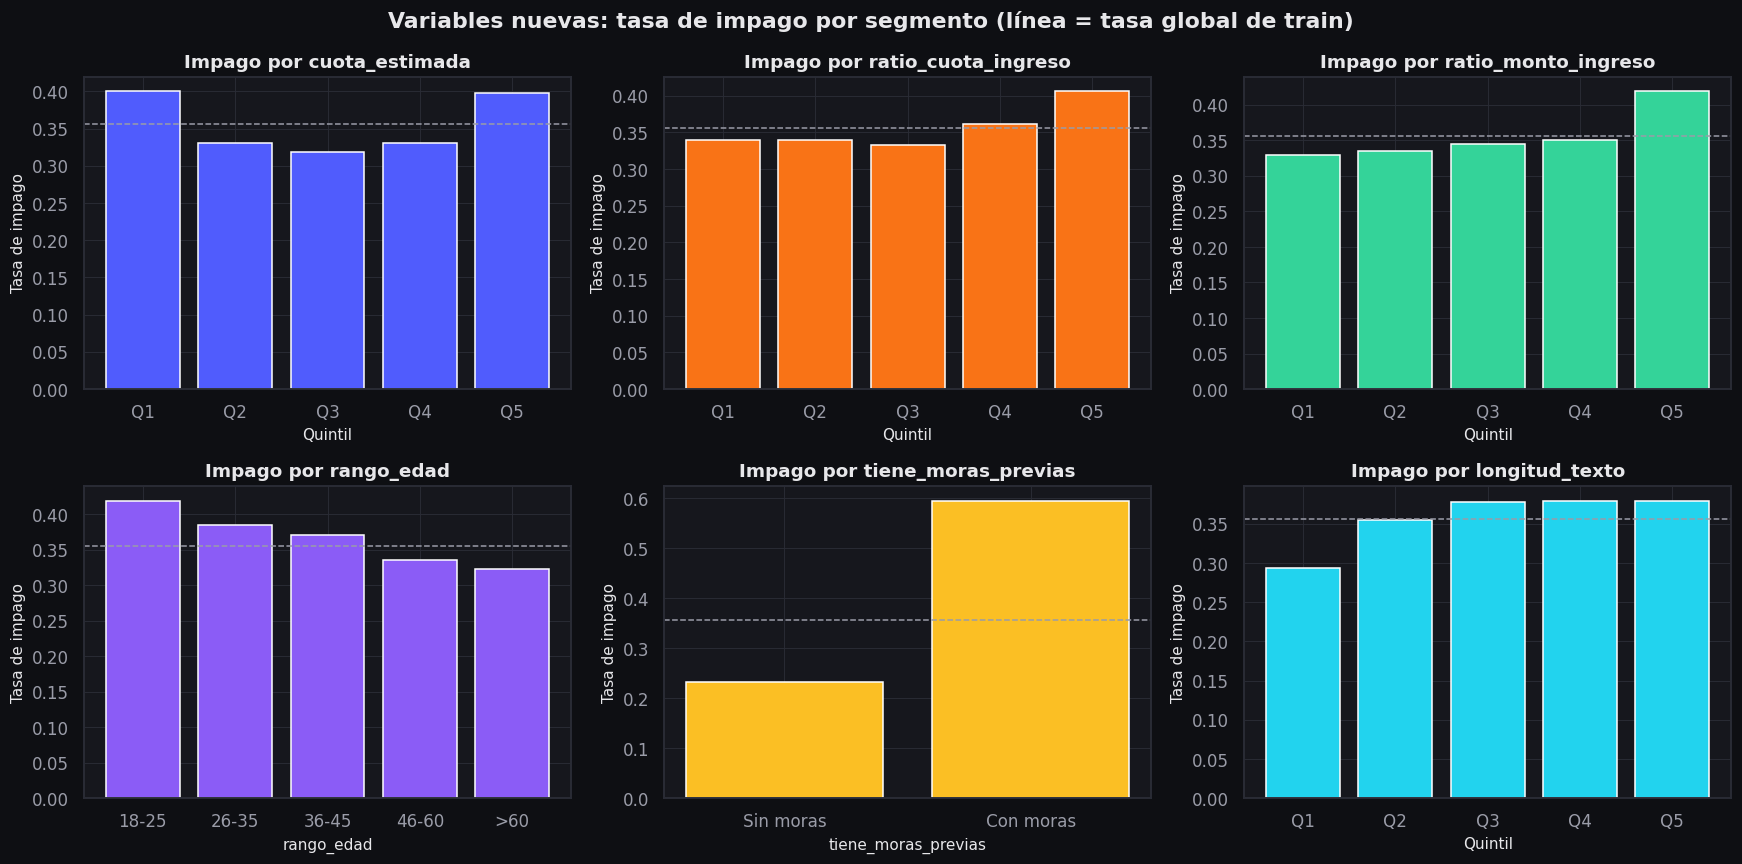

,spearman_con_default,rango_de_tasas_pp
cuota_estimada,-0.0040,8.1770
ratio_cuota_ingreso,0.0490,7.3440
ratio_monto_ingreso,0.0620,9.0100
tiene_moras_previas,0.3590,36.2940
longitud_texto,0.0610,8.5940
rango_edad,NaN,9.5910


In [12]:
def tasa_por(d: pd.DataFrame, col: str) -> pd.Series:
    if col == "rango_edad":
        return d.groupby(col)[T].mean().reindex(config.RANGO_EDAD_LABELS)
    if col == "tiene_moras_previas":
        return d.groupby(col)[T].mean().rename({0: "Sin moras", 1: "Con moras"})
    grupos = pd.qcut(d[col], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"], duplicates="drop")
    return d.groupby(grupos, observed=True)[T].mean()


tasa_global = train_fe[T].mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
senal = {}
for ax, col, color in zip(axes.ravel(), derivadas, SERIE):
    t = tasa_por(train_fe, col)
    senal[col] = t
    ax.bar(t.index.astype(str), t.values, color=color)
    ax.axhline(tasa_global, ls="--", color=PALETA["texto_suave"], lw=1)
    ax.set(title=f"Impago por {col}", xlabel="Quintil" if col not in ("rango_edad", "tiene_moras_previas") else col,
           ylabel="Tasa de impago")
    figura_front("barras", f"Tasa de impago por {col}",
                 {"categorias": [str(i) for i in t.index], "series": [{"nombre": "Tasa de impago", "valores": r4(t.values)}],
                  "referencias": [{"eje": "y", "valor": round(float(tasa_global), 4), "etiqueta": "tasa global"}]},
                 ejes={"x": "Quintil" if col not in ("rango_edad", "tiene_moras_previas") else col, "y": "Tasa de impago"},
                 clave=f"impago_por_{col}", opciones={"formato_y": "pct"})
plt.suptitle("Variables nuevas: tasa de impago por segmento (línea = tasa global de train)", fontweight="bold")
plt.show()
pd.DataFrame({"spearman_con_default": {c: train_fe[c].corr(train_fe[T], method="spearman") for c in derivadas
                                       if c != "rango_edad"},
              "rango_de_tasas_pp": {c: (senal[c].max() - senal[c].min()) * 100 for c in derivadas}}).round(3)

**Interpretación.** Las seis variables muestran diferencias en la tasa de impago (de 7,3 a 36,3 puntos
entre su segmento mínimo y máximo). `tiene_moras_previas` es la más fuerte: 23,3 % de impago sin moras frente a
59,6 % con moras. El impago **baja con la edad**, de 41,9 % (18-25) a 32,3 % (>60). Los ratios de capacidad de
pago son planos en los quintiles bajos (≈ 33-34 %) y suben en el quintil más alto (41,9 % en `ratio_monto_ingreso`
y 40,6 % en `ratio_cuota_ingreso`): el riesgo aparece cuando la carga es claramente excesiva. `cuota_estimada`
tiene forma de **U** (40,0 % en Q1, ≈ 32-33 % en el centro, 39,8 % en Q5), por eso su correlación de Spearman
es ≈ 0 (−0,004) aunque sí separa: una correlación lineal o monótona no ve esa relación. `longitud_texto` sube
de 29,4 % (Q1) a ≈ 38 % (Q3-Q5); esa señal se evalúa aparte en el paso 7.

## 5. P2.2 · Codificación de variables categóricas

- **One-Hot** para las nominales (sin orden natural): `estado_civil`, `situacion_laboral`, `tipo_vivienda` y
  `proposito`. `handle_unknown="ignore"` evita errores si en producción llega una categoría nueva.
- **Ordinal** para las que tienen orden: `nivel_educativo` y `rango_edad`, con el orden fijado en
  `config.ORDINALES` (no alfabético).

Ambos codificadores se ajustan **solo con train**.

In [13]:
cols = columnas_modelo()
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_fe[cols["nominales"]])
tabla_ohe = pd.DataFrame({"categorias_aprendidas": [", ".join(map(str, c)) for c in ohe.categories_],
                          "columnas_binarias": [len(c) for c in ohe.categories_]}, index=cols["nominales"])
print(f"One-Hot: {len(cols['nominales'])} variables nominales → {tabla_ohe['columnas_binarias'].sum()} columnas binarias")
display(tabla_ohe)
ejemplo_ohe = pd.DataFrame(ohe.transform(train_fe[cols["nominales"]].head(3)), columns=ohe.get_feature_names_out())
pd.concat([train_fe[cols["nominales"]].head(3).reset_index(drop=True), ejemplo_ohe.loc[:, ejemplo_ohe.any()]], axis=1)

One-Hot: 4 variables nominales → 20 columnas binarias


,categorias_aprendidas,columnas_binarias
estado_civil,"Casado, Divorciado, Soltero, Union_libre, Viudo",5
situacion_laboral,"Desconocido, Desempleado, Empleado, Independie...",5
tipo_vivienda,"Arriendo, Desconocido, Familiar, Propia",4
proposito,"Consolidacion_deuda, Educacion, Libre_inversio...",6


,estado_civil,situacion_laboral,tipo_vivienda,proposito,estado_civil_Casado,estado_civil_Soltero,estado_civil_Union_libre,situacion_laboral_Empleado,situacion_laboral_Independiente,situacion_laboral_Pensionado,tipo_vivienda_Propia,proposito_Vehiculo,proposito_Vivienda
0,Union_libre,Pensionado,Propia,Vivienda,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000
1,Casado,Independiente,Propia,Vivienda,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000
2,Soltero,Empleado,Propia,Vehiculo,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000


In [14]:
ordenc = OrdinalEncoder(categories=[config.ORDINALES[c] for c in cols["ordinales"]],
                        handle_unknown="use_encoded_value", unknown_value=-1).fit(train_fe[cols["ordinales"]])
mapeo = pd.DataFrame([{"variable": c, "categoria": cat, "codigo": i}
                      for c, cats in zip(cols["ordinales"], ordenc.categories_) for i, cat in enumerate(cats)])
display(mapeo.pivot(index="codigo", columns="variable", values="categoria"))
pd.concat([train_fe[cols["ordinales"]].head(5).reset_index(drop=True),
           pd.DataFrame(ordenc.transform(train_fe[cols["ordinales"]].head(5)),
                        columns=[f"{c}_codigo" for c in cols["ordinales"]]).astype(int)], axis=1)

variable,nivel_educativo,rango_edad
codigo,,
0,Primaria,18-25
1,Secundaria,26-35
2,Tecnico,36-45
3,Universitario,46-60
4,Posgrado,>60


,nivel_educativo,rango_edad,nivel_educativo_codigo,rango_edad_codigo
0,Secundaria,26-35,1,1
1,Tecnico,18-25,2,0
2,Primaria,46-60,0,3
3,Tecnico,46-60,2,3
4,Secundaria,>60,1,4


**Lectura.** One-Hot convierte 4 variables nominales en 20 columnas binarias; en
`situacion_laboral` y `tipo_vivienda` el codificador aprendió también la categoría `Desconocido`, que creó la
imputación. Cada fila tiene exactamente un 1 por variable (en el ejemplo se muestran solo las columnas activas).
El codificador ordinal respeta el orden natural (Primaria = 0 … Posgrado = 4; 18-25 = 0 … >60 = 4) y no el
alfabético, que pondría "Posgrado" antes que "Primaria". En el pipeline servido estos códigos se estandarizan
después.

## 6. P2.3 · Normalización (`MinMaxScaler`) frente a estandarización (`StandardScaler`)

Se ajustan ambas técnicas con train sobre las variables numéricas del modelo y se comparan.

In [15]:
num = cols["numericas"]
mm = MinMaxScaler().fit(train_fe[num])
ss = StandardScaler().fit(train_fe[num])
X_mm = pd.DataFrame(mm.transform(train_fe[num]), columns=num)
X_ss = pd.DataFrame(ss.transform(train_fe[num]), columns=num)
estad = ["mean", "std", "min", "max"]
ejemplo_vars = ["edad", "ingreso_mensual", "monto_credito", "puntaje_buro", "uso_cupo_tarjetas"]
comparacion = pd.concat({"original": train_fe[num].describe().T[estad], "MinMax": X_mm.describe().T[estad],
                         "Standard": X_ss.describe().T[estad]}, axis=1)
comparacion.loc[ejemplo_vars].round(3)

original                                                   MinMax                      Standard                 \
                             mean             std            min                max   mean    std    min    max     mean    std     min   
edad                      48.9360         18.0840        18.0000            80.0000 0.4990 0.2920 0.0000 1.0000  -0.0000 1.0000 -1.7110   
ingreso_mensual    2,595,665.6250  1,968,014.8140   312,000.0000    64,540,000.0000 0.0360 0.0310 0.0000 1.0000   0.0000 1.0000 -1.1600   
monto_credito     21,659,643.9580 32,184,295.0130 1,000,000.0000 1,033,300,000.0000 0.0200 0.0310 0.0000 1.0000   0.0000 1.0000 -0.6420   
puntaje_buro             708.7630        116.1030       150.0000           950.0000 0.6980 0.1450 0.0000 1.0000   0.0000 1.0000 -4.8130   
uso_cupo_tarjetas          0.4550          0.2510         0.0000             1.0000 0.4550 0.2510 0.0000 1.0000  -0.0000 1.0000 -1.8080   

                           
                      max  
edad               1.7180  
ingreso_mensual   31.4770  
monto_credito     31.4340  
puntaje_buro       2.0780  
uso_cupo_tarjetas  2.1680

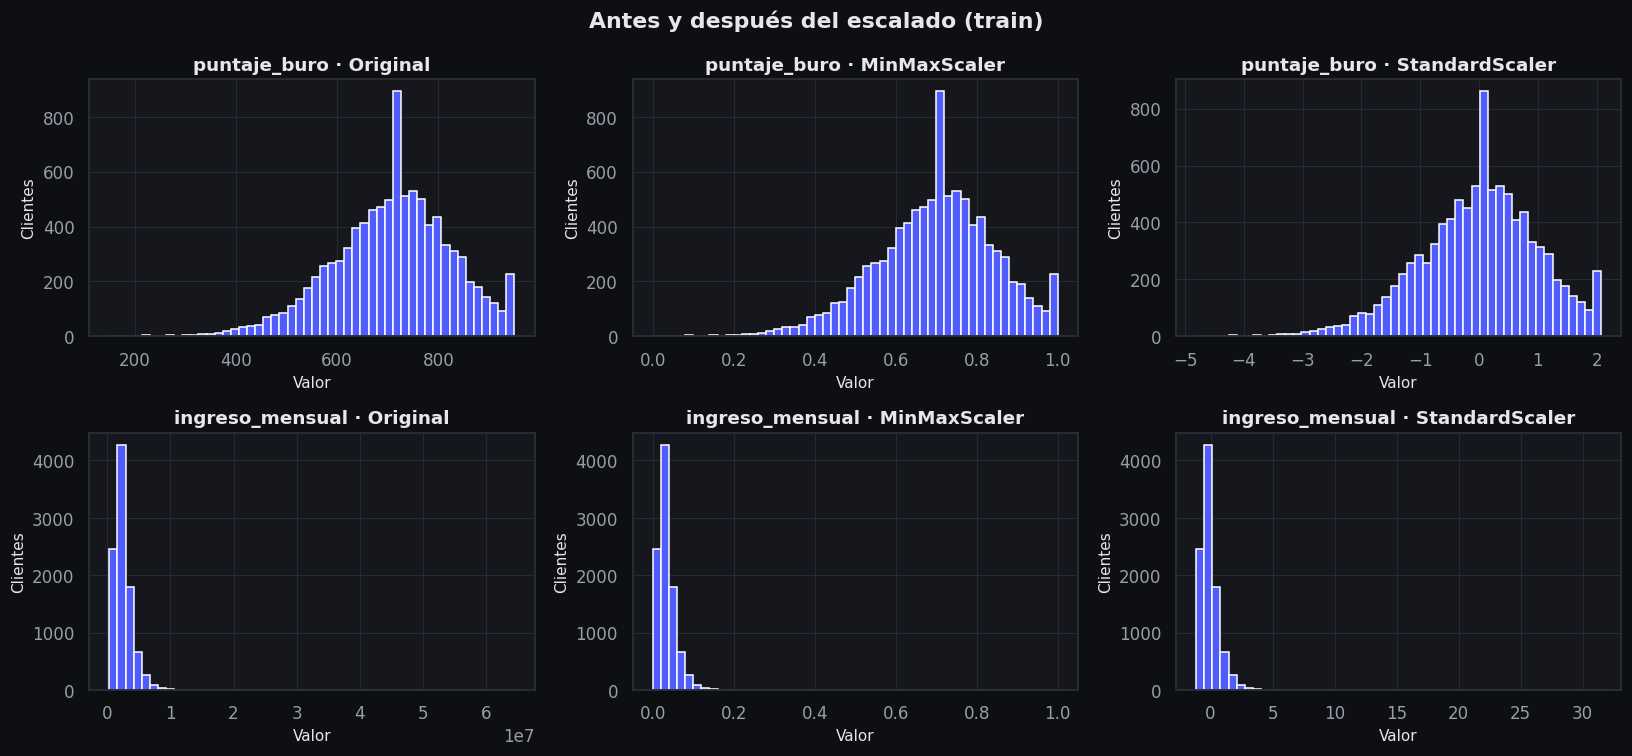

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for fila, col in enumerate(["puntaje_buro", "ingreso_mensual"]):
    for ax, (nombre, datos) in zip(axes[fila], [("Original", train_fe[col]), ("MinMaxScaler", X_mm[col]),
                                                 ("StandardScaler", X_ss[col])]):
        conteos, bordes = np.histogram(datos, bins=50)
        ax.hist(datos, bins=bordes, color=PALETA["acento"])
        ax.set(title=f"{col} · {nombre}", xlabel="Valor", ylabel="Clientes")
        figura_front("histograma", f"{col} · {nombre}",
                     {"bordes": r4(bordes), "series": [{"nombre": nombre, "conteos": conteos.tolist()}]},
                     ejes={"x": "Valor", "y": "Clientes"}, clave=f"escalado_{col}_{nombre.lower()}")
plt.suptitle("Antes y después del escalado (train)", fontweight="bold")
plt.show()

**Interpretación.** Las dos técnicas conservan la **forma** de la distribución y solo cambian la
escala. En `puntaje_buro`, una variable acotada, ambas se ven bien. En `ingreso_mensual`, con un máximo de 64,5
millones frente a una media de 2,6 millones, `MinMaxScaler` comprime casi todo cerca de 0 (media 0,036 y
desviación 0,031 en [0, 1]); lo mismo pasa con `monto_credito` (media 0,020). `StandardScaler` también refleja
el extremo (máximo de 31,5 desviaciones), pero deja a todas las variables centradas y comparables. **Se elige
`StandardScaler`**: es la escala natural de la regresión logística regularizada (la penalización trata igual a
todas las variables), de las redes neuronales y del PCA, y en el pipeline los extremos se recortan antes con el
capping p1-p99, que corrige su principal debilidad.

El escalador se ajusta en train y **solo se aplica** a test. Por eso test puede salir del rango [0, 1] de
`MinMaxScaler`: es la prueba de que no se usó información de test.

In [17]:
test_mm = pd.DataFrame(mm.transform(test_fe[num]), columns=num)
test_ss = pd.DataFrame(ss.transform(test_fe[num]), columns=num)
pd.DataFrame({"minmax_test_min": test_mm.min(), "minmax_test_max": test_mm.max(),
              "standard_test_media": test_ss.mean(), "standard_test_std": test_ss.std()}).loc[ejemplo_vars].round(3)

,minmax_test_min,minmax_test_max,standard_test_media,standard_test_std
edad,0.0000,1.0000,-0.0230,0.9940
ingreso_mensual,0.0010,0.6980,0.0200,1.0340
monto_credito,0.0000,0.5450,-0.0080,0.8980
puntaje_buro,0.1090,1.0000,0.0130,0.9930
uso_cupo_tarjetas,0.0000,1.0000,-0.0180,0.9830


**Lectura.** En test las medias estandarizadas no son exactamente 0 (entre −0,023 y
0,020) ni las desviaciones exactamente 1 (entre 0,898 y 1,034): el escalador usa los parámetros de train, como
debe ser. En estas variables test quedó dentro de [0, 1] porque los valores más extremos estaban en train (el
máximo del ingreso en test equivale a 0,698).

## 7. P2.E3 · Selección de características

Se transforma train con el mismo preprocesamiento del modelo servido (`Winsorizer` p1-p99 →
`build_preprocessor()`: mediana + `StandardScaler`, One-Hot, Ordinal) y se calculan tres criterios
**solo con train**: |correlación de Spearman| con `default`, información mutua (`mutual_info_classif`) e
importancia de impureza de un bosque de árboles poco profundos (más estable que un único árbol). Las
columnas One-Hot se agregan a su variable original (`variable_original`). `longitud_texto` se evalúa también,
aunque por diseño no entra al modelo tabular (el texto se mide aparte en el paso 7).

In [18]:
prep = Pipeline([("capping", Winsorizer()), ("pre", build_preprocessor())]).fit(train_fe)
Xt = pd.DataFrame(prep.transform(train_fe), columns=prep[-1].get_feature_names_out(), index=train_fe.index)
Xt_sel = Xt.assign(longitud_texto=StandardScaler().fit_transform(train_fe[["longitud_texto"]]).ravel())
y_tr = train_fe[T].to_numpy()
discretas = [variable_original(c) in cols["nominales"] or c in cols["ordinales"] or c == "tiene_moras_previas"
             for c in Xt_sel.columns]
rho = Xt_sel.corrwith(pd.Series(y_tr, index=Xt_sel.index), method="spearman").abs()
mi = pd.Series(mutual_info_classif(Xt_sel, y_tr, discrete_features=discretas, random_state=config.RANDOM_STATE),
               index=Xt_sel.columns)
bosque = RandomForestClassifier(n_estimators=60 if FAST else 300, max_depth=6, min_samples_leaf=20, n_jobs=-1,
                                random_state=config.RANDOM_STATE).fit(Xt_sel, y_tr)
imp = pd.Series(bosque.feature_importances_, index=Xt_sel.columns)
print(f"Matriz transformada de train: {Xt.shape[0]:,} filas × {Xt.shape[1]} columnas (+ longitud_texto para el análisis)")

criterios = pd.DataFrame({"abs_spearman": rho, "info_mutua": mi, "importancia_arbol": imp})
criterios["variable"] = [variable_original(c) for c in criterios.index]
seleccion = criterios.groupby("variable").agg(abs_spearman=("abs_spearman", "max"), info_mutua=("info_mutua", "sum"),
                                              importancia_arbol=("importancia_arbol", "sum"))
for c in ["abs_spearman", "info_mutua", "importancia_arbol"]:
    seleccion[f"rank_{c}"] = seleccion[c].rank(ascending=False)
seleccion["rank_promedio"] = seleccion.filter(like="rank_").mean(axis=1)
seleccion = seleccion.sort_values("rank_promedio")

Matriz transformada de train: 9,600 filas × 38 columnas (+ longitud_texto para el análisis)


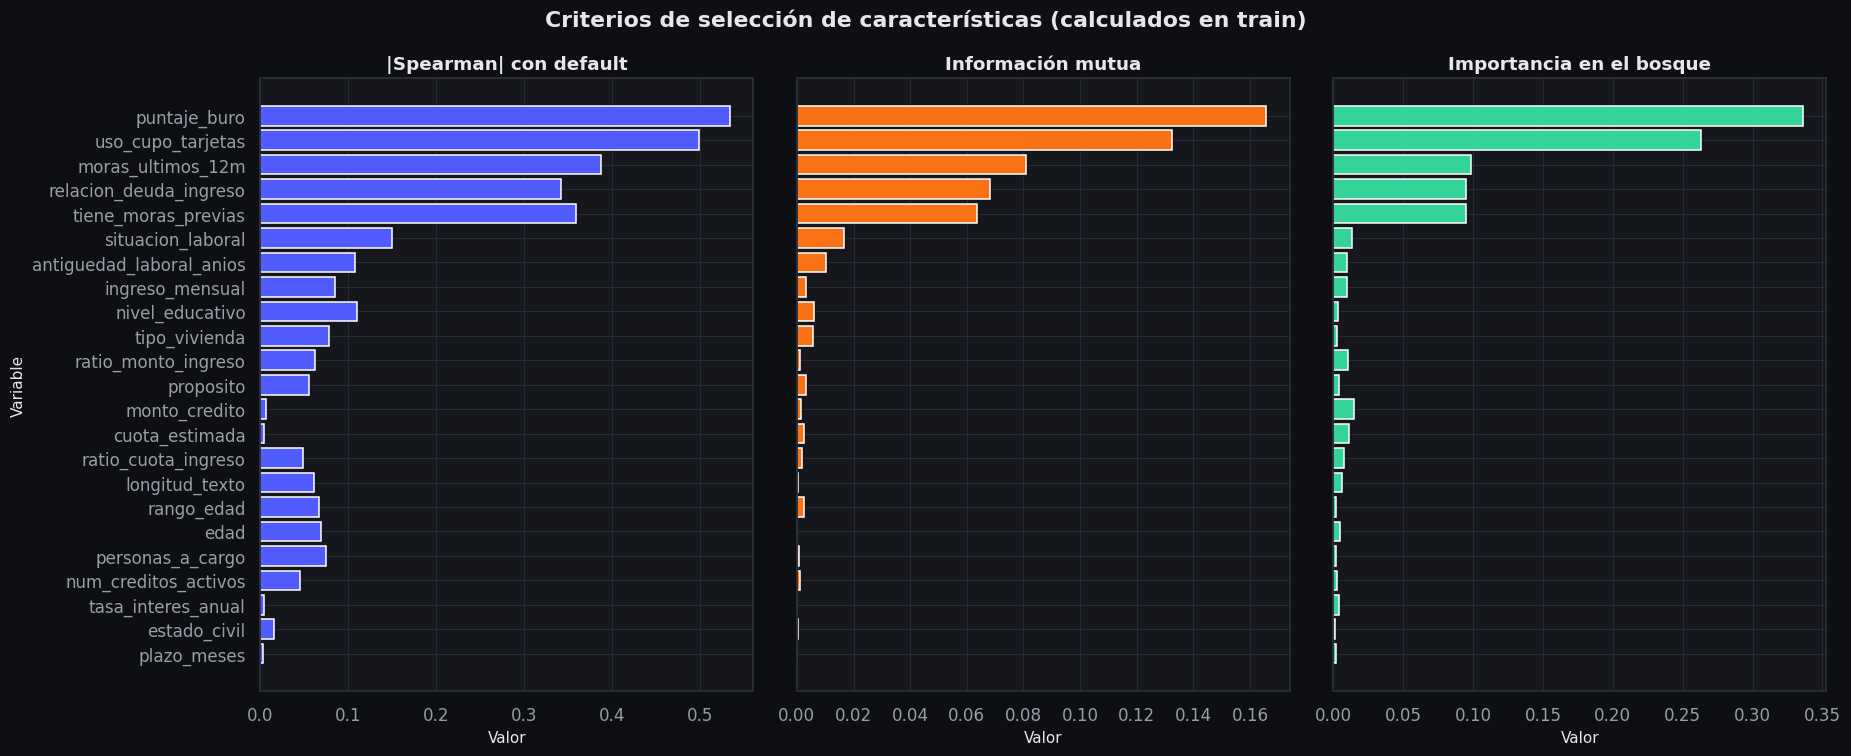

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharey=True)
orden = seleccion.index[::-1]
for ax, c, color, titulo in zip(axes, ["abs_spearman", "info_mutua", "importancia_arbol"], SERIE,
                                ["|Spearman| con default", "Información mutua", "Importancia en el bosque"]):
    ax.barh(orden, seleccion.loc[orden, c], color=color)
    ax.set(title=titulo, xlabel="Valor")
    figura_front("barras_h", f"Selección de características · {titulo}",
                 {"categorias": list(seleccion.index), "series": [{"nombre": titulo, "valores": r4(seleccion[c])}]},
                 ejes={"x": titulo, "y": "Variable"}, clave=f"seleccion_{c}")
axes[0].set_ylabel("Variable")
plt.suptitle("Criterios de selección de características (calculados en train)", fontweight="bold")
plt.show()

**Interpretación.** Los tres criterios coinciden en las cinco primeras: `puntaje_buro`,
`uso_cupo_tarjetas`, `moras_ultimos_12m`, `relacion_deuda_ingreso` y `tiene_moras_previas`; solo el buró y el uso
del cupo reúnen el 60 % de la importancia del bosque (33,6 % y 26,3 %). Les siguen `situacion_laboral` y
`antiguedad_laboral_anios`. `monto_credito` y `cuota_estimada` tienen Spearman ≈ 0 pero importancia > 1 % en el
bosque: su relación con el impago no es monótona (la U de la sección 4), algo que un árbol sí capta.

**Regla de selección.** Una variable se considera **seleccionada** si cumple al menos uno de estos
criterios: |Spearman| ≥ 0,02, información mutua ≥ 0,001 o importancia en el bosque ≥ 0,5 %. Las que no
cumplen ninguno se marcan como de **señal débil**. `sexo` no es candidata: está excluida por ética desde el
paso 1 y solo se usa para auditar. Las columnas del modelo se definen en un único lugar (`config`), que
este notebook no modifica: la tabla documenta la evidencia y la recomendación.

In [20]:
umbral = (seleccion["abs_spearman"] >= 0.02) | (seleccion["info_mutua"] >= 0.001) | (seleccion["importancia_arbol"] >= 0.005)
seleccion["supera_algun_criterio"] = umbral
seleccion["decision"] = np.where(seleccion.index == "longitud_texto", "Fuera del tabular (texto → paso 7)",
                                 np.where(umbral, "Seleccionada", "Señal débil (sigue en config; revisar en paso 5)"))
SELECCIONADAS = seleccion.index[seleccion["decision"] == "Seleccionada"].tolist()
SENAL_DEBIL = seleccion.index[seleccion["decision"].str.startswith("Señal débil")].tolist()
print(f"Seleccionadas ({len(SELECCIONADAS)}): {SELECCIONADAS}")
print(f"Señal débil   ({len(SENAL_DEBIL)}): {SENAL_DEBIL}")
seleccion.drop(columns=seleccion.filter(like="rank_").columns.drop("rank_promedio")).round(4)

Seleccionadas (19): ['puntaje_buro', 'uso_cupo_tarjetas', 'moras_ultimos_12m', 'relacion_deuda_ingreso', 'tiene_moras_previas', 'situacion_laboral', 'antiguedad_laboral_anios', 'ingreso_mensual', 'nivel_educativo', 'tipo_vivienda', 'ratio_monto_ingreso', 'proposito', 'monto_credito', 'cuota_estimada', 'ratio_cuota_ingreso', 'rango_edad', 'edad', 'personas_a_cargo', 'num_creditos_activos']
Señal débil   (3): ['tasa_interes_anual', 'estado_civil', 'plazo_meses']


,abs_spearman,info_mutua,importancia_arbol,rank_promedio,supera_algun_criterio,decision
variable,,,,,,
puntaje_buro,0.5335,0.1657,0.3360,1.0000,True,Seleccionada
uso_cupo_tarjetas,0.4988,0.1325,0.2634,2.0000,True,Seleccionada
moras_ultimos_12m,0.3873,0.0810,0.0986,3.0000,True,Seleccionada
relacion_deuda_ingreso,0.3415,0.0681,0.0952,4.3333,True,Seleccionada
tiene_moras_previas,0.3588,0.0635,0.0946,4.6667,True,Seleccionada
situacion_laboral,0.1491,0.0166,0.0130,6.3333,True,Seleccionada
antiguedad_laboral_anios,0.1080,0.0103,0.0096,8.6667,True,Seleccionada
ingreso_mensual,0.0843,0.0033,0.0100,10.0000,True,Seleccionada
nivel_educativo,0.1094,0.0061,0.0034,10.6667,True,Seleccionada


**Resultado.** 19 de las 22 variables candidatas del modelo superan al menos un criterio. Tres
tienen **señal débil**: `tasa_interes_anual` (|Spearman| 0,005, información mutua 0, importancia 0,42 %),
`estado_civil` (0,015; 0,0002; 0,13 %) y `plazo_meses` (0,003; 0; 0,16 %). Siguen en `config` porque es la
única fuente de las columnas del modelo: la tasa y el plazo ya entran también a través de `cuota_estimada` y
`ratio_cuota_ingreso`, y la regularización de la regresión logística reduce el peso de lo que no aporta. La
recomendación queda registrada en `feature_list.json` y se verifica con la importancia por permutación del
paso 5. `longitud_texto` sí muestra señal (Spearman 0,061), pero por diseño queda fuera del modelo tabular.

## 8. P2.5 · Reducción de dimensionalidad (PCA)

Regla de decisión del plan: si se necesitan **menos del 90 % de las componentes** para explicar el 95 % de
la varianza, PCA comprime de forma útil y se documenta; si no, se justifica no usarlo. Se ajusta sobre la
matriz escalada y codificada de train (la que recibe el modelo).

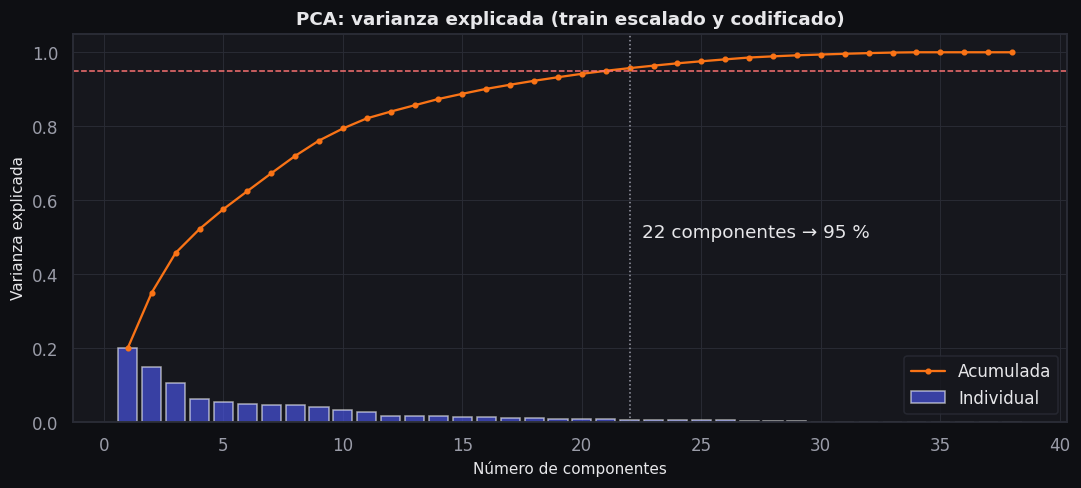

Componentes totales: 38 · para el 90 %: 16 · para el 95 %: 22 (58% del total)
Regla del plan: PCA comprime de forma útil (se documenta)


In [21]:
pca = PCA(random_state=config.RANDOM_STATE).fit(Xt)
var_acum = np.cumsum(pca.explained_variance_ratio_)
n_total = Xt.shape[1]
n_95 = int(np.argmax(var_acum >= 0.95) + 1)
n_90 = int(np.argmax(var_acum >= 0.90) + 1)
comprime = n_95 < 0.9 * n_total

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(range(1, n_total + 1), pca.explained_variance_ratio_, color=PALETA["acento"], alpha=0.6, label="Individual")
ax.plot(range(1, n_total + 1), var_acum, marker="o", ms=3, color=PALETA["programacion"], label="Acumulada")
ax.axhline(0.95, ls="--", color=PALETA["alto"], lw=1)
ax.axvline(n_95, ls=":", color=PALETA["texto_suave"], lw=1)
ax.text(n_95 + 0.5, 0.5, f"{n_95} componentes → 95 %", color=PALETA["texto"])
ax.set(title="PCA: varianza explicada (train escalado y codificado)", xlabel="Número de componentes",
       ylabel="Varianza explicada")
ax.legend()
plt.show()
figura_front("lineas", "PCA: varianza explicada acumulada",
             {"series": [{"nombre": "Acumulada", "x": list(range(1, n_total + 1)), "y": r4(var_acum)},
                         {"nombre": "Individual", "x": list(range(1, n_total + 1)), "y": r4(pca.explained_variance_ratio_)}],
              "referencias": [{"eje": "y", "valor": 0.95, "etiqueta": "95 %"},
                              {"eje": "x", "valor": n_95, "etiqueta": f"{n_95} componentes"}]},
             ejes={"x": "Número de componentes", "y": "Varianza explicada"}, clave="pca_varianza_acumulada",
             opciones={"formato_y": "pct"})
print(f"Componentes totales: {n_total} · para el 90 %: {n_90} · para el 95 %: {n_95} ({n_95 / n_total:.0%} del total)")
print("Regla del plan:", "PCA comprime de forma útil (se documenta)" if comprime else "PCA no compensa")

**Interpretación y decisión.** Tras la codificación hay 38 columnas; se necesitan 16 componentes para el 90 % de
la varianza y **22 (58 %) para el 95 %**. Según la regla del plan la compresión sería útil y queda
documentada, pero **no se usa en el pipeline** porque: (1) 38 columnas para 9.600 filas no es un problema de
dimensionalidad; (2) las componentes son combinaciones lineales que el analista y el regulador no pueden
interpretar, y la API debe explicar cada decisión con variables originales; (3) PCA maximiza varianza, no la
separación entre pagadores e impagos (se revisa en el paso 4); y (4) los modelos de árboles no lo necesitan. Se
conserva como herramienta de visualización.

## 9. Exportación reproducible a `db/processed/`

`preparar_procesados()` ejecuta de una vez la misma secuencia que se recorrió arriba (limpiar → dividir →
imputar con train → variables nuevas) y escribe `train.csv`, `test.csv` (limpios y **sin escalar**: el
escalado y la codificación viven dentro del pipeline) e `imputacion.json`. Se comprueba que su resultado es
idéntico al construido paso a paso, que no hay nulos ni duplicados y se registra el SHA-256 de cada archivo.

In [22]:
salida = preparar_procesados()
train_p, test_p = salida["train"], salida["test"]
pd.testing.assert_frame_equal(train_p, train_fe.sort_values(ID).reset_index(drop=True))
pd.testing.assert_frame_equal(test_p, test_fe.sort_values(ID).reset_index(drop=True))
train_csv, test_csv = cargar_procesados()
filas_exp = []
for nombre, d in {"train.csv": train_csv, "test.csv": test_csv}.items():
    ruta_csv = config.PROCESSED_DIR / nombre
    assert d.isna().sum().sum() == 0 and d.duplicated().sum() == 0 and d[ID].is_unique, nombre
    assert hash_archivo(ruta_csv) == salida["hashes"][nombre.removesuffix(".csv")]
    filas_exp.append({"archivo": ruta(ruta_csv), "filas": len(d), "columnas": d.shape[1],
                      "nulos": int(d.isna().sum().sum()), "duplicados_exactos": int(d.duplicated().sum()),
                      "duplicados_id": int(d[ID].duplicated().sum()), "tasa_default": round(float(d[T].mean()), 4),
                      "sha256": hash_archivo(ruta_csv)})
assert not set(train_csv[ID]) & set(test_csv[ID])
print("✔ preparar_procesados() reproduce exactamente el train y el test construidos paso a paso")
print("✔ 0 nulos, 0 duplicados exactos, 0 IDs repetidos y ningún cliente compartido entre train y test")
pd.DataFrame(filas_exp).set_index("archivo")

✔ preparar_procesados() reproduce exactamente el train y el test construidos paso a paso
✔ 0 nulos, 0 duplicados exactos, 0 IDs repetidos y ningún cliente compartido entre train y test


,filas,columnas,nulos,duplicados_exactos,duplicados_id,tasa_default,sha256
archivo,,,,,,,
db/processed/train.csv,9600,27,0,0,0,0.3556,1ce71f5f0123edb39b1d0120fd142e73c2a2c066bca40b...
db/processed/test.csv,2400,27,0,0,0,0.3558,8c1cb6a3dd0c05526e80c822c8b8211a08e0c2acd28a02...


### `feature_list.json` y `limites_atipicos.json`

`feature_list.json` documenta qué entra al modelo y por qué (columnas por tipo tomadas de
`config`/`columnas_modelo()`, variables derivadas, excluidas, sensibles, imputación y las decisiones de
selección y PCA). `limites_atipicos.json` guarda los límites p1-p99 que aprende `Winsorizer` en train: son
los mismos que aplica el pipeline servido (el tratamiento de atípicos se analiza en el paso 4).

In [23]:
JUSTIFICACION_DERIVADAS = {
    "cuota_estimada": "cuota mensual por amortización francesa (monto, tasa y plazo)",
    "ratio_cuota_ingreso": "capacidad de pago: cuota / ingreso",
    "ratio_monto_ingreso": "endeudamiento relativo: monto / ingreso",
    "rango_edad": "ciclo de vida (ordinal); se audita en equidad",
    "tiene_moras_previas": "historial de pago binario (moras_ultimos_12m > 0)",
    "longitud_texto": "detalle de la solicitud; solo EDA (el texto se evalúa en el paso 7)",
}
winsor = Winsorizer().fit(train_p)
feature_list = {
    "version": config.MODEL_VERSION,
    "target": T, "id": ID, "texto": config.TEXT_COL,
    "random_state": config.RANDOM_STATE, "test_size": config.TEST_SIZE,
    "numericas": cols["numericas"],
    "nominales_onehot": cols["nominales"],
    "ordinales": {c: config.ORDINALES[c] for c in cols["ordinales"]},
    "features_modelo": cols["numericas"] + cols["nominales"] + cols["ordinales"],
    "columnas_transformadas": int(Xt.shape[1]),
    "derivadas": {c: JUSTIFICACION_DERIVADAS[c] for c in derivadas},
    "excluidas": {ID: "identificador (no es una característica del cliente)",
                  config.SENSITIVE_COL: "variable sensible: solo auditoría de equidad (ADR-003)",
                  config.TEXT_COL: "texto libre: se modela aparte en el paso 7 (NLP)",
                  "longitud_texto": "derivada del texto: solo EDA, fuera del modelo tabular (paso 7)"},
    "sensibles_auditoria": {config.SENSITIVE_COL: "excluida del modelo; se audita el disparate impact",
                            **{c: "entra al modelo; se audita y existe la variante sin edad (ADR-003)"
                               for c in config.VARIABLES_EDAD}},
    "imputacion": {"mediana": reglas.mediana, "moda": reglas.moda, "desconocido": reglas.desconocido,
                   "texto": config.TEXTO_FALTANTE, "aprendida_en": "train"},
    "codificacion": {"nominales": "OneHotEncoder(handle_unknown='ignore')",
                     "ordinales": "OrdinalEncoder con el orden de config.ORDINALES"},
    "escalador": "StandardScaler",
    "capping": {"columnas": config.COLS_CAPPING, "cuantiles": list(config.CAPPING_QUANTILES),
                "archivo": "db/processed/limites_atipicos.json"},
    "seleccion": {"criterios": "abs_spearman >= 0.02 o info_mutua >= 0.001 o importancia_arbol >= 0.005",
                  "seleccionadas": SELECCIONADAS, "senal_debil": SENAL_DEBIL,
                  "nota": "las de señal débil siguen en config.NUM_MODELO/CAT_NOMINALES; se revisan con la "
                          "importancia por permutación del paso 5",
                  "tabla": seleccion[["abs_spearman", "info_mutua", "importancia_arbol", "decision"]]
                  .round(5).reset_index().to_dict(orient="records")},
    "pca": {"usado": False, "componentes_totales": n_total, "componentes_90pct": n_90, "componentes_95pct": n_95},
    "filas": {"train": len(train_p), "test": len(test_p)},
    "tasa_default": {"train": round(float(train_p[T].mean()), 4), "test": round(float(test_p[T].mean()), 4)},
    "sha256": salida["hashes"],
}
p_fl = guardar_json(feature_list, config.PROCESSED_DIR / "feature_list.json")
p_lim = guardar_json({"metodo": "capping p1-p99 con credit_risk.features.Winsorizer ajustado solo en train",
                      "cuantiles": list(config.CAPPING_QUANTILES),
                      "limites": {c: [lo, hi] for c, (lo, hi) in winsor.limites_.items()},
                      "sha256_train": salida["hashes"]["train"]}, config.PROCESSED_DIR / "limites_atipicos.json")
for p in [p_fl, p_lim, config.PROCESSED_DIR / "imputacion.json"]:
    print(f"✔ {ruta(p)} ({p.stat().st_size / 1024:.1f} KB)")
pd.DataFrame(winsor.limites_, index=["p1 (inferior)", "p99 (superior)"]).T

✔ db/processed/feature_list.json (9.8 KB)
✔ db/processed/limites_atipicos.json (0.8 KB)
✔ db/processed/imputacion.json (0.6 KB)


,p1 (inferior),p99 (superior)
ingreso_mensual,"578,000.0000","7,816,150.0000"
monto_credito,"2,006,000.0000","144,522,390.0000"
cuota_estimada,"76,469.6723","11,020,996.4013"
ratio_cuota_ingreso,0.0547,3.5718
ratio_monto_ingreso,1.6379,37.7458
antiguedad_laboral_anios,0.0000,52.3000
relacion_deuda_ingreso,0.0000,1.5000


In [24]:
display(Markdown(
    f"**Resumen calculado.** Del crudo ({rep['filas_iniciales']:,} filas) se eliminaron "
    f"{rep['duplicados_exactos']} duplicados exactos y {rep['duplicados_id']} por ID, y {rep['edades_invalidas']} "
    f"edades imposibles pasaron a nulo; quedaron {rep['filas_finales']:,} clientes únicos. La división estratificada "
    f"dejó {len(train_p):,} filas en train y {len(test_p):,} en test, con tasas de impago de "
    f"{train_p[T].mean():.2%} y {test_p[T].mean():.2%}. La imputación (aprendida en train) cubrió "
    f"{len(cols_nulas)} columnas y los CSV exportados tienen **0 nulos y 0 duplicados**. Se crearon "
    f"{len(derivadas)} variables; el modelo usa {len(feature_list['features_modelo'])} variables que se convierten "
    f"en {Xt.shape[1]} columnas tras la codificación. Selección: {len(SELECCIONADAS)} variables superan algún "
    f"criterio y {len(SENAL_DEBIL)} tienen señal débil ({', '.join(f'`{v}`' for v in SENAL_DEBIL)}). PCA necesita {n_95} de {n_total} componentes para el 95 % de la varianza "
    f"y no se usa en el pipeline. SHA-256 de train: `{salida['hashes']['train'][:16]}…`, de test: "
    f"`{salida['hashes']['test'][:16]}…`."))

**Resumen calculado.** Del crudo (12,144 filas) se eliminaron 144 duplicados exactos y 0 por ID, y 24 edades imposibles pasaron a nulo; quedaron 12,000 clientes únicos. La división estratificada dejó 9,600 filas en train y 2,400 en test, con tasas de impago de 35.56% y 35.58%. La imputación (aprendida en train) cubrió 8 columnas y los CSV exportados tienen **0 nulos y 0 duplicados**. Se crearon 6 variables; el modelo usa 22 variables que se convierten en 38 columnas tras la codificación. Selección: 19 variables superan algún criterio y 3 tienen señal débil (`tasa_interes_anual`, `estado_civil`, `plazo_meses`). PCA necesita 22 de 38 componentes para el 95 % de la varianza y no se usa en el pipeline. SHA-256 de train: `1ce71f5f0123edb3…`, de test: `8c1cb6a3dd0c0552…`.

## Conclusiones

- **P2.1 / P2.E1 · Faltantes y duplicados.** El crudo tenía 12.144 filas, 7 columnas con nulos (máximo
  9,21 % en `antiguedad_laboral_anios`, ninguna sobre el 40 %) y 144 duplicados exactos, que eran también los
  IDs repetidos. Quedaron **12.000 clientes únicos**; 24 edades imposibles pasaron a nulo y 8 columnas se
  imputaron con mediana, "Desconocido" o "Sin texto", con estadísticos aprendidos **solo en train**. Las reglas
  de catálogo y rangos no encontraron errores en este archivo, pero quedan activas para la API.
- **P2.4 · Variables nuevas.** Se crearon seis con justificación de negocio. `tiene_moras_previas` es la más
  discriminante (23,3 % frente a 59,6 % de impago); la edad y los ratios de capacidad de pago también separan,
  y `cuota_estimada` tiene una relación en U que la correlación no capta.
- **P2.6 / P2.E4 · División.** 80/20 estratificada (`random_state=42`) **antes** de imputar, codificar o
  escalar: 9.600 y 2.400 filas, con 35,56 % y 35,58 % de impago.
- **P2.2 / P2.3 / P2.E2 · Codificación y escalado.** One-Hot en 4 nominales (20 columnas), Ordinal en
  `nivel_educativo` y `rango_edad` con su orden natural, y `StandardScaler` elegido frente a `MinMaxScaler`, que
  comprime el ingreso y el monto cerca de 0 por sus extremos. Las 22 variables del modelo se convierten en 38
  columnas.
- **P2.E3 · Selección.** Spearman, información mutua y la importancia del bosque coinciden en buró, uso del
  cupo, moras y relación deuda/ingreso. 19 variables superan algún criterio; `tasa_interes_anual`,
  `estado_civil` y `plazo_meses` tienen señal débil y quedan señaladas para revisarse en el paso 5.
- **P2.5 · PCA.** 22 de 38 componentes explican el 95 % de la varianza; se documenta y no se usa en el
  pipeline, por explicabilidad.
- **Entregables.** `preparar_procesados()` reproduce exactamente el resultado paso a paso y escribe
  `train.csv` y `test.csv` con **0 nulos y 0 duplicados** (SHA-256 `1ce71f5f…` y `8c1cb6a3…`), además de
  `imputacion.json`, `feature_list.json` y `limites_atipicos.json` (límites p1-p99 aprendidos en train).